## 1. Environment Setup

In [52]:
import random
import sys
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 21
random.seed(SEED)
np.random.seed(SEED)

# Repo config
REPO_URL = "https://github.com/s26732-ctrl/ZUM_2026_KatarzynaWalkowicz.git"
REPO_DIR = Path("/content/ZUM_2026_KatarzynaWalkowicz")

# Dataset config
DATA_DIR = Path("/content/drive/MyDrive/Biome-Health-Project")
IMAGES_DIR = DATA_DIR / "images"
SPLITS_DIR = REPO_DIR / "splits"

print(f"Random seed: {SEED}")
print(f"Repository directory: {REPO_DIR}")
print(f"Dataset directory: {DATA_DIR}")

Random seed: 21
Repository directory: /content/ZUM_2026_KatarzynaWalkowicz
Dataset directory: /content/drive/MyDrive/Biome-Health-Project


In [53]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [54]:
# Check if repo is in session, if not - clone
if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        check=True
    )

sys.path.insert(0, str(REPO_DIR / "src"))
print("Repository ready")

Repository ready


## 2. Data Loading


In [ ]:
from metadata_loader import download_metadata, load_metadata

metadata_path = download_metadata(DATA_DIR)
metadata = load_metadata(metadata_path)

print(f"Images in metadata: {len(metadata['images'])}")
print(f"Categories: {len(metadata['categories'])}")

Metadata already exists
Images in metadata: 37075
Categories: 100


In [ ]:
train_ids = pd.read_csv(SPLITS_DIR / "train_ids.csv")
val_ids = pd.read_csv(SPLITS_DIR / "validation_ids.csv")

print(f"Train images: {len(train_ids)}")
print(f"Validation images: {len(val_ids)}")

display(train_ids.head())
display(val_ids.head())

Train images: 16954
Validation images: 4088


,id,group_id
0,2018_NB46_000062,NB46
1,2018_NB46_000070,NB46
2,2018_NB46_000114,NB46
3,2018_NB38_000118,NB38
4,2018_NB38_000125,NB38


,id,group_id
0,2018_NB35_000112,NB35
1,2018_NB35_000120,NB35
2,2018_NB34_000532,NB34
3,2018_NB34_000540,NB34
4,2018_NB35_000126,NB35


## 3. Train and Validation Data Prep

Combining the frozen split IDs with image metadata and class labels

In [ ]:
images_df = pd.DataFrame(metadata["images"])
annotations_df = pd.DataFrame(metadata["annotations"])
categories_df = pd.DataFrame(metadata["categories"])

# Keep only images with exactly one distinct category
categories_per_image = (
    annotations_df.groupby("image_id")["category_id"].nunique()
)

single_label_ids = categories_per_image[
    categories_per_image == 1
].index

# Assign one category to the appropriate image
image_labels = (
    annotations_df[
        annotations_df["image_id"].isin(single_label_ids)
    ][["image_id", "category_id"]]
    .drop_duplicates()
)

# Add image filenames etc
image_data = (
    images_df
    .merge(image_labels, left_on="id", right_on="image_id")
    .merge(
        categories_df[["id", "name"]],
        left_on="category_id",
        right_on="id",
        suffixes=("", "_category")
    )
)

# Select images using the frozen split IDs
train_df = train_ids.merge(
    image_data[["id", "file_name", "name"]],
    on="id",
    how="left",
    validate="one_to_one"
)

val_df = val_ids.merge(
    image_data[["id", "file_name", "name"]],
    on="id",
    how="left",
    validate="one_to_one"
)

train_df = train_df.rename(columns={"name": "label"})
val_df = val_df.rename(columns={"name": "label"})

print("Train:", train_df.shape)
print("Validation:", val_df.shape)

display(train_df.head())

Train: (16954, 4)
Validation: (4088, 4)


,id,group_id,file_name,label
0,2018_NB46_000062,NB46,2018_NB46_000062.JPG,impala
1,2018_NB46_000070,NB46,2018_NB46_000070.JPG,impala
2,2018_NB46_000114,NB46,2018_NB46_000114.JPG,impala
3,2018_NB38_000118,NB38,2018_NB38_000118.JPG,gazelle_thomsons
4,2018_NB38_000125,NB38,2018_NB38_000125.JPG,gazelle_thomsons


In [ ]:
# Double check on data load
assert train_df[["file_name", "label"]].notna().all().all()
assert val_df[["file_name", "label"]].notna().all().all()

print("Image metadata and labels loaded successfully")

Image metadata and labels loaded successfully


## 4. Train and Validation Images Download

Whole image batch is too large to fit in the available storage space - the download will be assisted by immediate resizing to 256x256px.(Download & resize step took me ~1h30min)

In [ ]:
from io import BytesIO

import requests
from PIL import Image, ImageOps
from image_downloader import IMAGE_BASE_URL

IMAGE_SIZE = (256, 256)

filenames = (
    pd.concat([train_df["file_name"], val_df["file_name"]])
    .drop_duplicates()
    .tolist()
)

def download_resized_images(filenames, images_dir):

    images_dir = Path(images_dir)
    images_dir.mkdir(parents=True, exist_ok=True)

    downloaded = 0
    skipped = 0
    failed = []

    with requests.Session() as session:
        for filename in filenames:

            image_path = images_dir / filename

            if image_path.exists() and image_path.stat().st_size > 0:
                skipped += 1
                continue

            try:
                response = session.get(
                    IMAGE_BASE_URL + filename,
                    timeout=60
                )
                response.raise_for_status()

                with Image.open(BytesIO(response.content)) as image:

                    image = ImageOps.exif_transpose(image)
                    image = image.convert("RGB")

                    image = ImageOps.pad(
                        image,
                        IMAGE_SIZE,
                        method=Image.Resampling.LANCZOS,
                        color=(0, 0, 0)
                    )

                    image_path.parent.mkdir(
                        parents=True,
                        exist_ok=True
                    )

                    image.save(
                        image_path,
                        format="JPEG",
                        quality=85
                    )

                downloaded += 1

            except (requests.RequestException, OSError, ValueError) as error:
                failed.append(filename)
                print(f"Failed: {filename} - {error}")

    print(f"Downloaded and resized: {downloaded}")
    print(f"Skipped: {skipped}")
    print(f"Failed: {len(failed)}")

    return failed


print(f"Images to process: {len(filenames)}")

failed_downloads = download_resized_images(
    filenames,
    IMAGES_DIR
)

Images to process: 21042
Downloaded and resized: 21042
Skipped: 0
Failed: 0


## 5. Trivial Baseline - DummyClassifier

A DummyClassifier with the "most_frequent" strategy is used as a trivial baseline.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

import time

# Prepare labels
y_train = train_df["label"]
y_val = val_df["label"]

# Dummy features (image content is not used)
X_train_dummy = np.zeros((len(y_train), 1))
X_val_dummy = np.zeros((len(y_val), 1))

# Train trivial baseline
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

start_time = time.perf_counter()

dummy_model.fit(X_train_dummy, y_train)

dummy_train_time = time.perf_counter() - start_time

# Predict on validation
y_pred_dummy = dummy_model.predict(X_val_dummy)

# Evaluate
dummy_results = {
    "model": "DummyClassifier",
    "macro_f1": f1_score(y_val, y_pred_dummy, average="macro", zero_division=0),
    "accuracy": accuracy_score(y_val, y_pred_dummy),
    "macro_precision": precision_score(y_val, y_pred_dummy, average="macro", zero_division=0),
    "macro_recall": recall_score(y_val, y_pred_dummy, average="macro", zero_division=0),
    "train_time_seconds": dummy_train_time
}

display(pd.DataFrame([dummy_results]))

print("Predicted class:", dummy_model.classes_[np.argmax(dummy_model.class_prior_)])

,model,macro_f1,accuracy,macro_precision,macro_recall,train_time_seconds
0,DummyClassifier,0.027647,0.198875,0.016573,0.083333,0.017488


Predicted class: wildebeest


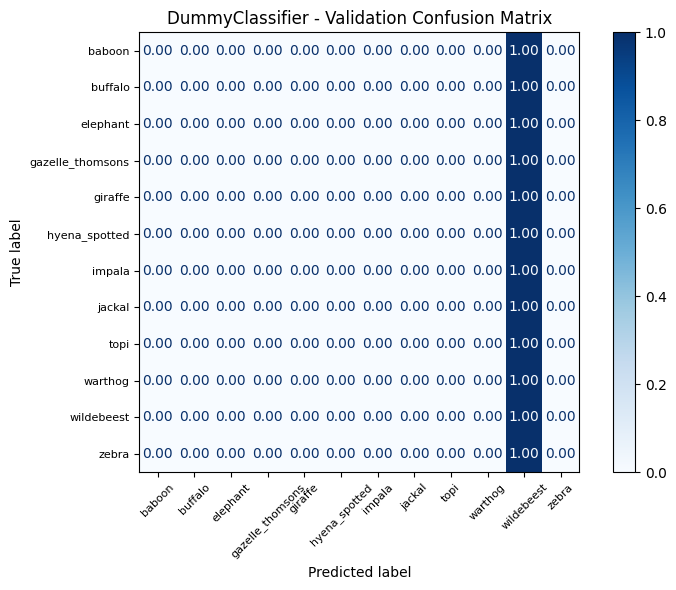

In [ ]:
# Confusion matrix for DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_dummy,
    labels=dummy_model.classes_,
    normalize="true",
    values_format=".2f",
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

ax.set_title("DummyClassifier - Validation Confusion Matrix")
ax.tick_params(axis="both", labelsize=8)

plt.tight_layout()
plt.show()

## 6. Baseline A: HOG + SVM

The baseline uses Histogram of Oriented Gradients (HOG) to extract visual features from grayscale images and a Support Vector Machine (SVM) for classification.

### 6.1 HOG Feature Extraction

HOG features are extracted from grayscale 128×128 images (8100 float32 features per image). Cached features are reused to avoid repeating expensive extraction.

In [ ]:
# Extracting features for one image
from skimage.feature import hog
from PIL import Image

HOG_IMAGE_SIZE = (128, 128)

def extract_hog_features(image_path):

    with Image.open(image_path) as image:
        image = image.convert("L")
        image = image.resize(HOG_IMAGE_SIZE, Image.Resampling.LANCZOS)
        image_array = np.asarray(image)

    features = hog(
        image_array,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    )

    return features.astype(np.float32)


In [ ]:
# Extracting features on the whole batch
from tqdm.auto import tqdm

HOG_FEATURES_DIR = DATA_DIR / "hog_features"
HOG_FEATURES_DIR.mkdir(parents=True, exist_ok=True)


def extract_dataset_features(df, images_dir, desc):
    features = []
    labels = []

    for row in tqdm(
        df.itertuples(index=False),
        total=len(df),
        desc=desc
    ):
        image_path = images_dir / row.file_name

        features.append(extract_hog_features(image_path))
        labels.append(row.label)

    return np.asarray(features, dtype=np.float32), np.asarray(labels)


# Extract only if cached features are missing
for df, filename, description in [
    (train_df, "train_hog.npz", "Train HOG"),
    (val_df, "validation_hog.npz", "Validation HOG")
]:
    feature_path = HOG_FEATURES_DIR / filename

    if feature_path.exists():
        print(f"Using cached features: {filename}")
    else:
        X, y = extract_dataset_features(
            df,
            IMAGES_DIR,
            desc=description
        )

        np.savez_compressed(feature_path, X=X, y=y)
        print(f"Saved features: {filename}")

Using cached features: train_hog.npz
Using cached features: validation_hog.npz


In [ ]:
# Load cached HOG features
with np.load(HOG_FEATURES_DIR / "train_hog.npz") as data:
    X_train = data["X"]
    y_train = data["y"]

with np.load(HOG_FEATURES_DIR / "validation_hog.npz") as data:
    X_val = data["X"]
    y_val = data["y"]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)

Train: (16954, 8100) (16954,)
Validation: (4088, 8100) (4088,)



### 6.2 SGD-based Linear SVM Training

A linear SVM is optimized with stochastic gradient descent (SGDClassifier, loss="hinge"). Standardization is fitted on training data only

In [ ]:
from sklearn.linear_model import SGDClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import joblib

# Define SGD-based linear SVM
sgd_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SGDClassifier(
        loss="hinge",
        alpha=0.0001,
        max_iter=3000,
        tol=1e-3,
        random_state=SEED
    ))
])

# Train model
start_time = time.perf_counter()

sgd_model.fit(X_train, y_train)

sgd_train_time = time.perf_counter() - start_time

print(f"Training time: {sgd_train_time:.2f} seconds")

# Save trained model
MODEL_DIR = DATA_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    sgd_model,
    MODEL_DIR / "hog_sgd_svm.joblib"
)

print("SGD-based SVM model saved successfully!")

Training time: 1473.74 seconds
SGD-based SVM model saved successfully!


### 6.3 Validation Evaluation
Evaluate the trained SGD-based linear SVM on the frozen validation split

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# Predict on validation
y_pred_sgd = sgd_model.predict(X_val)

# Calculate metrics
sgd_results = {
    "model": "HOG + SGD-SVM",
    "macro_f1": f1_score(y_val, y_pred_sgd, average="macro", zero_division=0),
    "accuracy": accuracy_score(y_val, y_pred_sgd),
    "macro_precision": precision_score(
        y_val, y_pred_sgd, average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_val, y_pred_sgd, average="macro", zero_division=0
    ),
    "train_time_seconds": sgd_train_time
}

for metric, value in sgd_results.items():
    print(f"{metric}: {value}")

model: HOG + SGD-SVM
macro_f1: 0.12134691476935289
accuracy: 0.24070450097847357
macro_precision: 0.20124715704312143
macro_recall: 0.1220447995986688
train_time_seconds: 1473.7354363050017


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_val,
        y_pred_sgd,
        zero_division=0
    )
)

                  precision    recall  f1-score   support

          baboon       0.00      0.00      0.00        52
         buffalo       0.50      0.04      0.08       123
        elephant       0.00      0.00      0.00        41
gazelle_thomsons       0.30      0.43      0.36      1050
         giraffe       0.23      0.06      0.10       204
   hyena_spotted       0.12      0.12      0.12       190
          impala       0.46      0.10      0.17       672
          jackal       0.05      0.02      0.03        53
            topi       0.26      0.06      0.10       220
         warthog       0.06      0.11      0.08       178
      wildebeest       0.22      0.41      0.29       813
           zebra       0.21      0.12      0.15       492

        accuracy                           0.24      4088
       macro avg       0.20      0.12      0.12      4088
    weighted avg       0.27      0.24      0.22      4088



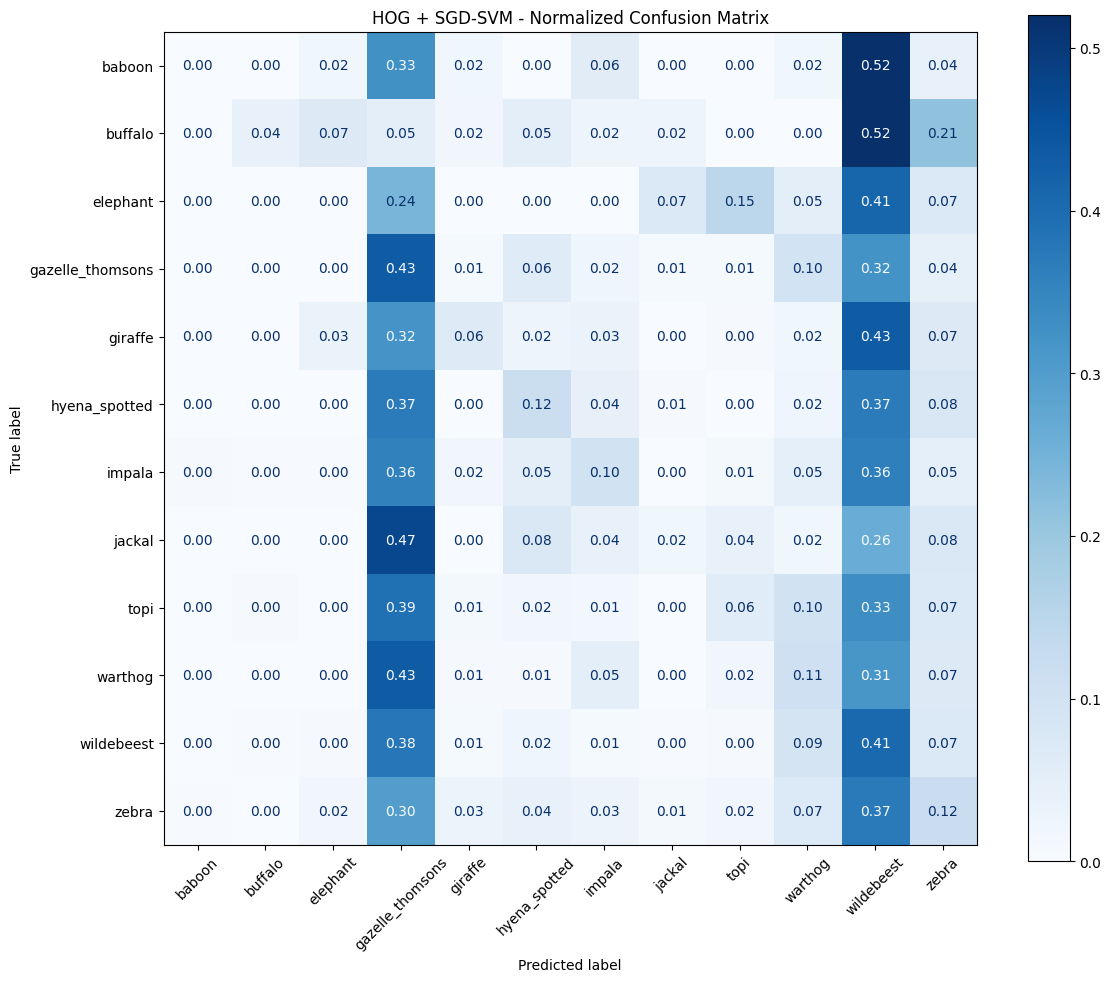

In [ ]:
# Confusion matrix for Baseline A
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_sgd,
    labels=sgd_model.named_steps["classifier"].classes_,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

ax.set_title("HOG + SGD-SVM - Normalized Confusion Matrix")

plt.tight_layout()
plt.show()

### Comment: validation results initial observations

The HOG + SGD-SVM baseline achieved a macro F1-score of **0.1213** and an accuracy of **24.07%** on the validation set.

The confusion matrix reveals a strong tendency to predict two classes: 'gazelle_thomsons' and 'wildebeest'. This pattern occurs across most of the actual species, including visually distinct animals such as elephants, giraffes and baboons.

These results suggest that the HOG representation combined with a linear SVM has limited ability to distinguish between the selected species. Class imbalance and differences between camera locations may also contribute to the observed errors.

Next, a qualitative analysis of misclassified images will be performed to further investigate potential causes.

### 6.4 Qualitative error analysis

To better understand the mistakes made by Baseline A model, five misclassified validation images form different true classes wil be examined.

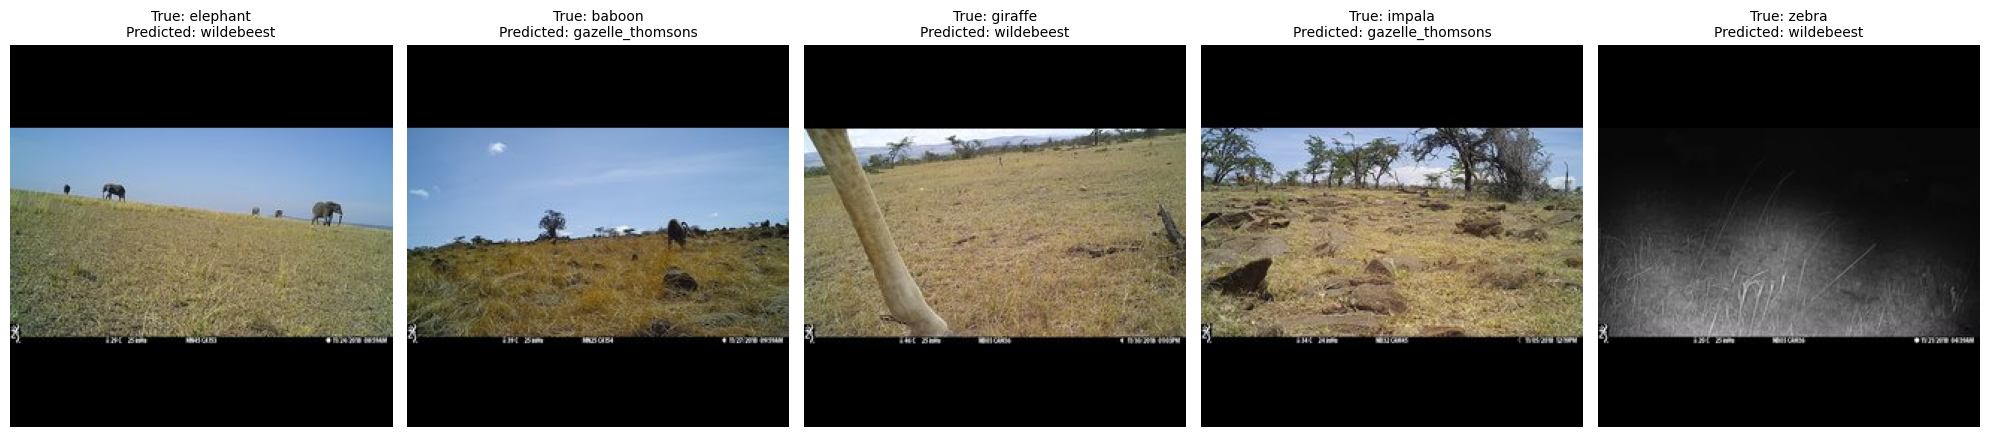

In [56]:
# Select five types of classification errors
error_pairs = [
    ("elephant", "wildebeest"),
    ("baboon", "gazelle_thomsons"),
    ("giraffe", "wildebeest"),
    ("impala", "gazelle_thomsons"),
    ("zebra", "wildebeest")
]

# Combine validation metadata with predictions
errors_df = val_df.copy()
errors_df["prediction"] = y_pred_sgd

# Display one example for each error type
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, (true_label, predicted_label) in zip(axes, error_pairs):

    matches = errors_df[
        (errors_df["label"] == true_label) &
        (errors_df["prediction"] == predicted_label)
    ]

    if matches.empty:
        ax.set_title("No matching error")
        ax.axis("off")
        continue

    sample = matches.sample(n=1, random_state=SEED).iloc[0]

    image_path = IMAGES_DIR / sample["file_name"]

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(
        f"True: {true_label}\nPredicted: {predicted_label}",
        fontsize=10
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

### Comment: Qualitative error analysis

Observations on the misclassified images:
- small / distant animals: animals sometimes occupy only a small portion of the image
- background dominance: environmental elements occupy large areas of the images
- poor visibility: some animals are partially hidden by other elements
- low-light conditions: an image captured at night with no clearly visible animal

These observations suggest that the baseline model may struggle when distinctive animal features are weak or absent. Resizing images to 128 x 128 px may further reduce important visual details.

Tthese explanations, however, still remain hypotheses based on a small sample of errors rather than confirmed causes.